In [ ]:
#%pip install keras tensorflow

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ----------------- ---------------------- 1.0/2.4 MB 2.8 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 3.5 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 3.5 MB/s  0:00:00
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/384.1 MB 4.4 MB/s eta 0:01:27
   ---------------------------------------- 1.3/384.1 MB 3.3 MB/s eta 0:01:57
   ---------------------------------------- 1.8/384.1 MB 3.7 MB/s eta 0:01:44
   ---------------------------------------- 1.8/384.1 MB 3.7 MB/s eta 0:01:44
   ---------------------------------------- 1.8/384.1 MB 3.7 MB/s eta 0:01:44
   ---------------------------------------- 1.8/384.1 MB 3.7 MB/s eta 0:01:44
   ---------------------------------------- 1.8/384.1 MB 3.7 MB/s eta 0:01:44
   -----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [3]:
import keras

from keras.models import Sequential
from keras.layers import Input, Dense, Flatten
from keras.datasets import mnist
from keras.utils import to_categorical

Next, download the MNIST dataset. It comes with TensorFlow and contains 28 x 28 pixel images of handwritten digits labelled from 0 to 9.

In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


The data ends ip in 4 different NumPy tensors:
- x_train,
- y_train,
- x_test,
- y_test.

Train data contains the input features and target labels.

### Preprocessing

In [5]:
x_train = x_train / 255.0
x_test = x_test / 255.0
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [6]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
    ])

In [7]:
model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [8]:
model.fit(x_train, y_train, epochs=5, batch_size=32)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9260 - loss: 0.2585
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9639 - loss: 0.1210
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9741 - loss: 0.0877
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9798 - loss: 0.0690
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9836 - loss: 0.0578


In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9739 - loss: 0.0894
Test accuracy: 0.9739000201225281


In [10]:
x_train.shape

(60000, 28, 28)

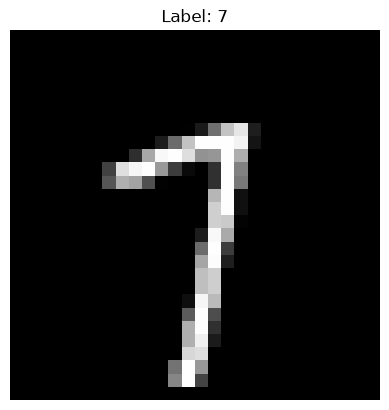

In [11]:

import matplotlib.pyplot as plt

# Visualize a sample image
sample_number = 42
plt.imshow(x_train[sample_number], cmap='gray')
plt.title(f'Label: {y_train[sample_number].argmax()}')  # Use .argmax() to get the label as an integer
plt.axis('off')  # Hide the axes
plt.show()